In [1]:
2# Clone the repository
!git clone https://github.com/UniversalDependencies/UD_Sanskrit-Vedic.git

# Check what files we have
!ls UD_Sanskrit-Vedic/

Cloning into 'UD_Sanskrit-Vedic'...
remote: Enumerating objects: 85, done.
remote: Counting objects: 100% (85/85), done.
remote: Compressing objects: 100% (63/63), done.
remote: Total 85 (delta 45), reused 57 (delta 20), pack-reused 0 (from 0)
Receiving objects: 100% (85/85), 6.14 MiB | 8.14 MiB/s, done.
Resolving deltas: 100% (45/45), done.
CONTRIBUTING.md  LICENSE.txt  sa_vedic-ud-dev.conllu   sa_vedic-ud-train.conllu
eval.log	 README.md    sa_vedic-ud-test.conllu  stats.xml


In [2]:
# Install conllu parser
!pip install conllu

In [3]:
import conllu
from collections import defaultdict
import matplotlib.pyplot as plt
import numpy as np

In [5]:
#get all compounds from the file
import conllu
def extract_compounds(sentences):
  compounds = []
  for sent_index, sent in enumerate(sentences):
    compound_tokens= []
    for i, token in enumerate(sent):
      #checking if
      if token['feats'] and 'Compound' in str(token['feats']):
        compound_tokens.append(token)
      else:
        if compound_tokens:
          compound_tokens.append(token)

          #save the compound
          compound_info= {
              'sent_id': sent_index,
              'text': sent.metadata.get('text', ' '),
              'tokens': compound_tokens,
              'lemmas': [t['lemma'] for t in compound_tokens],
              'forms': [t['form'] for t in compound_tokens],
              'heads': [t['head'] for t in compound_tokens],
              'deprels': [t['deprel'] for t in compound_tokens],
              'length': len(compound_tokens)

          }
          compounds.append(compound_info)
          compound_tokens = []
        #cases where the compound is at the enc
    if compound_tokens:
      compound_info= {
              'sent_id': sent_index,
              'text': sent.metadata.get('text', ' '),
              'tokens': compound_tokens,
              'lemmas': [t['lemma'] for t in compound_tokens],
              'forms': [t['form'] for t in compound_tokens],
              'heads': [t['head'] for t in compound_tokens],
              'deprels': [t['deprel'] for t in compound_tokens],
              'length': len(compound_tokens)

          }
  return compounds

# Load the training data
with open('UD_Sanskrit-Vedic/sa_vedic-ud-train.conllu', 'r', encoding='utf-8') as f:
    train_data = conllu.parse(f.read())

train_compounds= extract_compounds(train_data)
print(f"Total compounds in training data: {len(train_compounds)}")


Total compounds in training data: 7469


Total compounds in training data: 7469
  2 words: 6717 compounds (89.9%)
  3 words: 482 compounds (6.5%)
  4 words: 143 compounds (1.9%)
  5 words: 56 compounds (0.7%)
  6 words: 26 compounds (0.3%)
  7 words: 17 compounds (0.2%)
  8 words: 11 compounds (0.1%)
  9 words: 3 compounds (0.0%)
  10 words: 2 compounds (0.0%)
  11 words: 5 compounds (0.1%)
  12 words: 1 compounds (0.0%)
  13 words: 1 compounds (0.0%)
  15 words: 1 compounds (0.0%)
  18 words: 2 compounds (0.0%)
  22 words: 1 compounds (0.0%)
  26 words: 1 compounds (0.0%)

Most common dependency relations in compounds:
  nmod: 3213
  obj: 1535
  compound:coord: 1507
  conj: 1500
  acl: 1317
  amod: 838
  root: 836
  flat: 825
  nummod: 620
  obl: 594


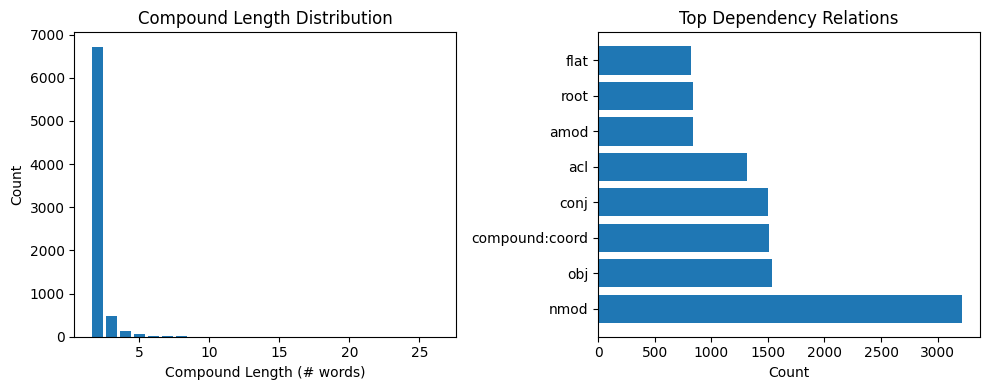

In [6]:
#compound analysis
import matplotlib.pyplot as plt
from collections import Counter

compound_lengths = [len(c['tokens']) for c in train_compounds]
compound_relations=[]
for c in train_compounds:
  compound_relations.extend(c['deprels'])

print(f"Total compounds in training data: {len(train_compounds)}")
length_counts = Counter(compound_lengths)
for length in sorted(length_counts.keys()):
    print(f"  {length} words: {length_counts[length]} compounds ({length_counts[length]/len(train_compounds)*100:.1f}%)")
print(f"\nMost common dependency relations in compounds:")
relation_counts = Counter(compound_relations)
for rel, count in relation_counts.most_common(10):
    print(f"  {rel}: {count}")

# Visualize length distribution
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.bar(length_counts.keys(), length_counts.values())
plt.xlabel('Compound Length (# words)')
plt.ylabel('Count')
plt.title('Compound Length Distribution')

plt.subplot(1, 2, 2)
top_relations = dict(relation_counts.most_common(8))
plt.barh(list(top_relations.keys()), list(top_relations.values()))
plt.xlabel('Count')
plt.title('Top Dependency Relations')
plt.tight_layout()
plt.show()


In [8]:

#setting up and loading the data
# we primarily focus on 2 word compounds
import json
import numpy as np
from collections import Counter, defaultdict
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
import conllu

def extract_compounds_fixed(sentences):
    """
    Extract compounds  - compound includes tokens marked Compound=Yes
    """
    compounds = []
    for sent_idx, sent in enumerate(sentences):
        i = 0
        while i < len(sent):
            token = sent[i]
            # Check if this token starts a compound
            if token['feats'] and 'Compound' in str(token['feats']):
                compound_tokens = [token]
                # Collect all consecutive Compound=Yes tokens
                j = i + 1
                while j < len(sent):
                    if sent[j]['feats'] and 'Compound' in str(sent[j]['feats']):
                        compound_tokens.append(sent[j])
                        j += 1
                    else:
                        # Add the next token (head of compound)
                        compound_tokens.append(sent[j])
                        break

                compound_info = {
                    'sent_id': sent_idx,
                    'text': sent.metadata.get('text', ''),
                    'tokens': compound_tokens,
                    'lemmas': [t['lemma'] for t in compound_tokens],
                    'forms': [t['form'] for t in compound_tokens],
                    'heads': [t['head'] for t in compound_tokens],
                    'deprels': [t['deprel'] for t in compound_tokens],
                    'length': len(compound_tokens)
                }
                compounds.append(compound_info)
                # Skip past this compound
                i = j + 1
            else:
                i += 1

    return compounds

# Load data
with open('UD_Sanskrit-Vedic/sa_vedic-ud-train.conllu', 'r', encoding='utf-8') as f:
    train_sentences = conllu.parse(f.read())

with open('UD_Sanskrit-Vedic/sa_vedic-ud-dev.conllu', 'r', encoding='utf-8') as f:
    dev_sentences = conllu.parse(f.read())

with open('UD_Sanskrit-Vedic/sa_vedic-ud-test.conllu', 'r', encoding='utf-8') as f:
    test_sentences = conllu.parse(f.read())

# extract compounds
train_compounds = extract_compounds_fixed(train_sentences)
dev_compounds = extract_compounds_fixed(dev_sentences)
test_compounds = extract_compounds_fixed(test_sentences)

print(f"\nTotal compounds extracted:")
print(f"Training:   {len(train_compounds)} compounds")
print(f"Dev:        {len(dev_compounds)} compounds")
print(f"Test:       {len(test_compounds)} compounds")

# Filter to 2-word compounds
train_2word = [c for c in train_compounds if c['length'] == 2]
dev_2word = [c for c in dev_compounds if c['length'] == 2]
test_2word = [c for c in test_compounds if c['length'] == 2]

print(f"\nTotal 2-word compounds extracted:")
print(f"Training:   {len(train_2word)} compounds")
print(f"Dev:        {len(dev_2word)} compounds")
print(f"Test:       {len(test_2word)} compounds")



Total compounds extracted:
Training:   7469 compounds
Dev:        897 compounds
Test:       902 compounds

Total 2-word compounds extracted:
Training:   6717 compounds
Dev:        844 compounds
Test:       824 compounds


In [20]:

#transition-based parser
class TransitionBasedParser:
    def __init__(self):
      self.stack=[]
      self.buffer=[]
      self.arcs=[]

    def initialize(self,tokens):
      """ initialize the parser with the input tokens"""
      self.stack=[]
      self.buffer=tokens.copy()
      self.arcs=[]

    def shift(self):
      """shift the first token from the buffer to the stack"""
      if len(self.buffer)>0:
        self.stack.append(self.buffer.pop(0))
        return True
      return False

    def left_arc(self, label):
      """ LEFT-ARC where stack [-1] becomes head of the stack[-2] """
      if len(self.stack)>=2:
        head=self.stack[-1]
        dependent = self.stack[-2]
        self.arcs.append({
            'head': head['id'],
            'dependent': dependent['id'],
            'label': label
        })
        self.stack.pop(-2)
        return True
      return False

    def right_arc(self,label):
      """ RIGHT-ARC : stack[-2] becomes head of the stack[-1]"""
      if len(self.stack)>=2:
        head=self.stack[-2]
        dependent=self.stack[-1]
        self.arcs.append({
            'head': head['id'],
            'dependent': dependent['id'],
            'label': label
        })
        self.stack.pop(-1)
        return True
      return False

    def is_terminal(self):
      """ check if the parser has completed the parsing """
      return len(self.buffer)==0 and len(self.stack)==1
    def get_configuration(self):
      """ return the current configuration as string """
      stack_str = [t['lemma'] for t in self.stack] if self.stack else []
      buffer_str = [t['lemma'] for t in self.buffer] if self.buffer else []
      return f"Stack:{stack_str}, Buffer:{buffer_str}"



In [10]:
#normalizing the token ids
def normalize_compound_ids(compound):
    tokens = compound['tokens']
    #  mapping from old IDs to new IDs
    old_to_new = {}
    for i, token in enumerate(tokens):
        old_to_new[token['id']] = i + 1

    #  new tokens with renumbered IDs
    new_tokens = []
    for i, token in enumerate(tokens):
        new_token = token.copy()
        new_token['id'] = i + 1

        # Update head
        if token['head'] in old_to_new:
            new_token['head'] = old_to_new[token['head']]
        elif token['head'] == 0:
            new_token['head'] = 0
        else:

            new_token['head'] = 0

        new_tokens.append(new_token)


    normalized = compound.copy()
    normalized['tokens'] = new_tokens
    return normalized

train_2word_normalized = [normalize_compound_ids(c) for c in train_2word]
dev_2word_normalized = [normalize_compound_ids(c) for c in dev_2word]
test_2word_normalized = [normalize_compound_ids(c) for c in test_2word]


train_2word = train_2word_normalized
dev_2word = dev_2word_normalized
test_2word = test_2word_normalized



In [11]:
def get_gold_actions_for_2word_compound(compound):
    """
    For a 2-word compound, derive the gold action sequence

    Sequence is always:
    1. SHIFT (move word1 to stack)
    2. SHIFT (move word2 to stack)
    3. LEFT-ARC(label) or RIGHT-ARC(label) based on gold dependencies
    """
    tokens = compound['tokens']

    if len(tokens) != 2:
        return None

    word1, word2 = tokens[0], tokens[1]
    # Determine arc direction from gold annotations
    # If word1's head is word2, then: word2 → word1 (RIGHT-ARC from word2's perspective)
    # If word2's head is word1, then: word1 → word2
    word1_head = word1['head']
    word2_head = word2['head']
    # Convert to indices in compound
    word1_idx = 0
    word2_idx = 1
    actions = []

    # Always start with two shifts
    actions.append(('SHIFT', None))
    actions.append(('SHIFT', None))

    # Determine arc direction
    # After 2 SHIFTs: stack = [word1, word2], buffer = []

    if word1_head == word2['id']:
        # word1 depends on word2: word2 ← word1
        # This means word2 is head, so LEFT-ARC
        actions.append(('LEFT-ARC', word1['deprel']))
    elif word2_head == word1['id']:
        # word2 depends on word1: word1 ← word2
        # This means word1 is head, so RIGHT-ARC
        actions.append(('RIGHT-ARC', word2['deprel']))
    elif word2_head == 0:
        # word2 is root, word1 depends on word2
        actions.append(('LEFT-ARC', word1['deprel']))
    elif word1_head == 0:
        # word1 is root, word2 depends on word1
        actions.append(('RIGHT-ARC', word2['deprel']))
    else:
        # Both point outside - shouldn't happen in proper 2-word compound
        # Default to LEFT-ARC
        actions.append(('LEFT-ARC', word1['deprel']))

    return actions
test_compound = train_2word[0]

actions = get_gold_actions_for_2word_compound(test_compound)
print(f"Gold actions: {actions}")
parser = TransitionBasedParser()
parser.initialize(test_compound['tokens'])
for action_type, label in actions:
    if action_type == 'SHIFT':
        parser.shift()
    elif action_type == 'LEFT-ARC':
        parser.left_arc(label)
    elif action_type == 'RIGHT-ARC':
        parser.right_arc(label)

print(f"Finally arcs: {parser.arcs}")


Gold actions: [('SHIFT', None), ('SHIFT', None), ('LEFT-ARC', 'obl:soc')]
Finally arcs: [{'head': 2, 'dependent': 1, 'label': 'obl:soc'}]


In [12]:
#  encoders
pos_encoder = LabelEncoder()
case_encoder = LabelEncoder()
gender_encoder = LabelEncoder()
number_encoder = LabelEncoder()
all_pos = []
all_case = []
all_gender = []
all_number = []

for comp in train_2word:
    for token in comp['tokens']:
        all_pos.append(token['upos'])
        feats = token.get('feats', {}) or {}
        all_case.append(feats.get('Case', 'None'))
        all_gender.append(feats.get('Gender', 'None'))
        all_number.append(feats.get('Number', 'None'))

pos_encoder.fit(all_pos + ['NULL'])
case_encoder.fit(all_case + ['NULL'])
gender_encoder.fit(all_gender + ['NULL'])
number_encoder.fit(all_number + ['NULL'])

print(f"Unique POS tags: {len(pos_encoder.classes_)}")
print(f"Unique cases: {len(case_encoder.classes_)}")

def extract_features(stack, buffer):
    """
    Extract features from parser configuration

    Features:
    - Top 2 items on stack (POS, case, gender, number)
    - Top item in buffer (POS, case)
    - Agreement features
    """
    features = []
    # Stack top (s0)
    if len(stack) >= 1:
        token = stack[-1]
        feats = token.get('feats', {}) or {}
        features.append(pos_encoder.transform([token['upos']])[0])
        features.append(case_encoder.transform([feats.get('Case', 'None')])[0])
        features.append(gender_encoder.transform([feats.get('Gender', 'None')])[0])
        features.append(number_encoder.transform([feats.get('Number', 'None')])[0])
    else:
        features.extend([
            pos_encoder.transform(['NULL'])[0],
            case_encoder.transform(['NULL'])[0],
            gender_encoder.transform(['NULL'])[0],
            number_encoder.transform(['NULL'])[0]
        ])
    # Stack second (s1)
    if len(stack) >= 2:
        token = stack[-2]
        feats = token.get('feats', {}) or {}
        features.append(pos_encoder.transform([token['upos']])[0])
        features.append(case_encoder.transform([feats.get('Case', 'None')])[0])
        features.append(gender_encoder.transform([feats.get('Gender', 'None')])[0])
        features.append(number_encoder.transform([feats.get('Number', 'None')])[0])
    else:
        features.extend([
            pos_encoder.transform(['NULL'])[0],
            case_encoder.transform(['NULL'])[0],
            gender_encoder.transform(['NULL'])[0],
            number_encoder.transform(['NULL'])[0]
        ])
    # Buffer first (b0)
    if len(buffer) >= 1:
        token = buffer[0]
        feats = token.get('feats', {}) or {}
        features.append(pos_encoder.transform([token['upos']])[0])
        features.append(case_encoder.transform([feats.get('Case', 'None')])[0])
    else:
        features.extend([
            pos_encoder.transform(['NULL'])[0],
            case_encoder.transform(['NULL'])[0]
        ])
    if len(stack) >= 2:
        feats1 = stack[-1].get('feats', {}) or {}
        feats2 = stack[-2].get('feats', {}) or {}

        # if same case
        features.append(1 if feats1.get('Case') == feats2.get('Case') else 0)
        # if same gender?
        features.append(1 if feats1.get('Gender') == feats2.get('Gender') else 0)
        # if same number?
        features.append(1 if feats1.get('Number') == feats2.get('Number') else 0)
        # if same POS?
        features.append(1 if stack[-1]['upos'] == stack[-2]['upos'] else 0)
    else:
        features.extend([0, 0, 0, 0])

    return np.array(features)

parser = TransitionBasedParser()
parser.initialize(test_compound['tokens'])
parser.shift()
features = extract_features(parser.stack, parser.buffer)
print(f"Feature vector shape: {features.shape}")
print(f"Feature vector: {features}")


Unique POS tags: 9
Unique cases: 10
Feature vector shape: (14,)
Feature vector: [3 8 4 2 4 6 2 1 0 7 0 0 0 0]


In [13]:
def create_training_data(compounds):
    """
    Create training examples by simulating oracle parsing
    """
    training_examples = []
    for comp in compounds:
        # Get gold action sequence
        gold_actions = get_gold_actions_for_2word_compound(comp)
        if gold_actions is None:
            continue
        parser = TransitionBasedParser()
        parser.initialize(comp['tokens'])

        for action_type, label in gold_actions:
            features = extract_features(parser.stack, parser.buffer)
            if action_type == 'SHIFT':
                action_label = 'SHIFT'
            else:
                action_label = f"{action_type}:{label}"


            training_examples.append({
                'features': features,
                'action': action_label
            })

            if action_type == 'SHIFT':
                parser.shift()
            elif action_type == 'LEFT-ARC':
                parser.left_arc(label)
            elif action_type == 'RIGHT-ARC':
                parser.right_arc(label)

    return training_examples

train_examples = create_training_data(train_2word)
dev_examples = create_training_data(dev_2word)

# Check action distribution
action_counts = Counter([ex['action'] for ex in train_examples])
print(f"\nAction relation distribution:")
for action, count in action_counts.most_common(15):
    print(f"  {action}: {count} ({count/len(train_examples)*100:.1f}%)")


Action relation distribution:
  SHIFT: 13434 (66.7%)
  LEFT-ARC:nmod: 2480 (12.3%)
  LEFT-ARC:obj: 758 (3.8%)
  LEFT-ARC:amod: 714 (3.5%)
  LEFT-ARC:compound:coord: 559 (2.8%)
  LEFT-ARC:nummod: 553 (2.7%)
  RIGHT-ARC:flat: 446 (2.2%)
  LEFT-ARC:acl: 250 (1.2%)
  LEFT-ARC:obl: 236 (1.2%)
  LEFT-ARC:det: 174 (0.9%)
  LEFT-ARC:advmod: 66 (0.3%)
  LEFT-ARC:obl:agent: 53 (0.3%)
  LEFT-ARC:obl:instr: 53 (0.3%)
  LEFT-ARC:obl:goal: 46 (0.2%)
  LEFT-ARC:obl:lmod: 41 (0.2%)


In [14]:
# Encode actions
action_encoder = LabelEncoder()
all_actions = [ex['action'] for ex in train_examples] + [ex['action'] for ex in dev_examples]
action_encoder.fit(all_actions)

print(f"Total unique actions: {len(action_encoder.classes_)}")

# Convert to matrices
X_train = np.array([ex['features'] for ex in train_examples])
y_train = action_encoder.transform([ex['action'] for ex in train_examples])

X_dev = np.array([ex['features'] for ex in dev_examples])
y_dev = action_encoder.transform([ex['action'] for ex in dev_examples])


# Train classifier
action_classifier = LogisticRegression(max_iter=1000, random_state=42)
action_classifier.fit(X_train, y_train)

# Evaluate
train_pred = action_classifier.predict(X_train)
dev_pred = action_classifier.predict(X_dev)

train_acc = accuracy_score(y_train, train_pred)
dev_acc = accuracy_score(y_dev, dev_pred)

print(f"Training Accuracy: {train_acc:.3f}")
print(f"Dev Accuracy:      {dev_acc:.3f}")



Total unique actions: 49
Training Accuracy: 0.876
Dev Accuracy:      0.872


In [15]:
def greedy_parse(tokens, classifier):
    """
    Parse a 2-word compound using greedy decoding
    """
    parser = TransitionBasedParser()
    parser.initialize(tokens)

    while not parser.is_terminal():
        # extract features
        features = extract_features(parser.stack, parser.buffer)
        action_idx = classifier.predict([features])[0]
        action = action_encoder.inverse_transform([action_idx])[0]

        if action == 'SHIFT':
            parser.shift()
        elif action.startswith('LEFT-ARC:'):
            label = action.split(':', 1)[1]
            parser.left_arc(label)
        elif action.startswith('RIGHT-ARC:'):
            label = action.split(':', 1)[1]
            parser.right_arc(label)
        else:
            if len(parser.buffer) > 0:
                parser.shift()
            else:
                break

    return parser.arcs


test_comp = dev_2word[0]
print(f"\nCompound: {test_comp['lemmas']}")
predicted_arcs = greedy_parse(test_comp['tokens'], action_classifier)
print(f"Predicted arcs: {predicted_arcs}")

# Show gold arcs
gold_arcs = []
for token in test_comp['tokens']:
    if token['head'] != 0:
        gold_arcs.append({
            'head': token['head'],
            'dependent': token['id'],
            'label': token['deprel']
        })
print(f"Gold arcs: {gold_arcs}")



Compound: ['unmocana', 'pratirūpa']
Predicted arcs: [{'head': 2, 'dependent': 1, 'label': 'obj'}]
Gold arcs: [{'head': 2, 'dependent': 1, 'label': 'nmod'}]


In [16]:
def evaluate_parser(compounds, classifier):
    """
    Evaluate parser using standard dependency parsing metrics:
    UAS (Unlabeled Attachment Score): % of correct head assignments
    LAS (Labeled Attachment Score): % of correct head + label
    """
    total_tokens = 0
    correct_unlabeled = 0
    correct_labeled = 0

    for comp in compounds:
        predicted_arcs = greedy_parse(comp['tokens'], classifier)
        gold_arcs = {}
        for token in comp['tokens']:
            if token['head'] != 0:
                gold_arcs[token['id']] = {
                    'head': token['head'],
                    'label': token['deprel']
                }

        pred_arcs = {}
        for arc in predicted_arcs:
            pred_arcs[arc['dependent']] = {
                'head': arc['head'],
                'label': arc['label']
            }


        for token in comp['tokens']:
            if token['id'] in gold_arcs:
                total_tokens += 1
                gold = gold_arcs[token['id']]

                if token['id'] in pred_arcs:
                    pred = pred_arcs[token['id']]
                    if pred['head'] == gold['head']:
                        correct_unlabeled += 1
                        if pred['label'] == gold['label']:
                            correct_labeled += 1

    uas = correct_unlabeled / total_tokens if total_tokens > 0 else 0
    las = correct_labeled / total_tokens if total_tokens > 0 else 0
    return uas, las, total_tokens

# Evaluate on dev set
dev_uas, dev_las, dev_tokens = evaluate_parser(dev_2word, action_classifier)
print(f"Total tokens evaluated: {dev_tokens}")
print(f"UAS (Unlabeled Attachment Score): {dev_uas:.3f}")
print(f"LAS (Labeled Attachment Score):   {dev_las:.3f}")

Total tokens evaluated: 841
UAS (Unlabeled Attachment Score): 0.943
LAS (Labeled Attachment Score):   0.620


In [17]:
# Error Analysis by Relation Type
from collections import defaultdict
error_analysis = defaultdict(lambda: {'total': 0, 'errors': [], 'correct': 0})
for comp in dev_2word:
    predicted_arcs = greedy_parse(comp['tokens'], action_classifier)

    # build gold arcs
    for token in comp['tokens']:
        if token['head'] != 0:
            relation = token['deprel']
            error_analysis[relation]['total'] += 1
            # check if predicted correctly
            is_correct = False
            for pred_arc in predicted_arcs:
                if (pred_arc['dependent'] == token['id'] and
                    pred_arc['head'] == token['head'] and
                    pred_arc['label'] == relation):
                    is_correct = True
                    break
            if is_correct:
                error_analysis[relation]['correct'] += 1
            else:
                error_analysis[relation]['errors'].append(comp)

#  results
print("Performance by Relation Type:")
for rel in sorted(error_analysis.keys(), key=lambda x: error_analysis[x]['total'], reverse=True):
    stats = error_analysis[rel]
    acc = stats['correct'] / stats['total'] if stats['total'] > 0 else 0
    print(f"{rel:15} {stats['total']:4d} compounds  {acc:.3f} accuracy")

Performance by Relation Type:
nmod             338 compounds  0.772 accuracy
amod             101 compounds  0.723 accuracy
obj               80 compounds  0.562 accuracy
compound:coord    71 compounds  0.465 accuracy
nummod            67 compounds  0.955 accuracy
flat              47 compounds  0.043 accuracy
obl               32 compounds  0.562 accuracy
acl               31 compounds  0.742 accuracy
det               27 compounds  0.000 accuracy
obl:agent          7 compounds  0.000 accuracy
advmod             6 compounds  0.167 accuracy
obl:soc            6 compounds  0.000 accuracy
obl:source         6 compounds  0.000 accuracy
obl:instr          4 compounds  0.000 accuracy
obl:goal           3 compounds  0.000 accuracy
xcomp              3 compounds  0.000 accuracy
compound           2 compounds  0.000 accuracy
obl:path           2 compounds  0.000 accuracy
nmod:pred          2 compounds  0.000 accuracy
case:sim           2 compounds  0.500 accuracy
iobj               1 compounds

In [19]:
# Show specific error examples
error_examples = []
for comp in dev_2word[:100]:  # Check first 100
    predicted_arcs = greedy_parse(comp['tokens'], action_classifier)

    # bnuild gold and pred dicts
    gold_dict = {}
    for token in comp['tokens']:
        if token['head'] != 0:
            gold_dict[token['id']] = {'head': token['head'], 'label': token['deprel'], 'token': token}

    pred_dict = {}
    for arc in predicted_arcs:
        pred_dict[arc['dependent']] = {'head': arc['head'], 'label': arc['label']}

    # find errors
    for dep_id, gold in gold_dict.items():
        if dep_id in pred_dict:
            pred = pred_dict[dep_id]

            # head error or label error
            if pred['head'] != gold['head'] or pred['label'] != gold['label']:
                error_examples.append({
                    'compound': comp,
                    'gold': gold,
                    'pred': pred
                })

# show first 5 errors
print(f"\nShowing first 5 errors (out of {len(error_examples)} total):\n")

for i, err in enumerate(error_examples[:5]):
    comp = err['compound']
    gold = err['gold']
    pred = err['pred']

    print(f"{i+1}. Compound: {' + '.join(comp['lemmas'])}")
    print(f"   Gold: head={gold['head']}, label={gold['label']}")
    print(f"   Pred: head={pred['head']}, label={pred['label']}")

    if pred['head'] != gold['head']:
        print(f"   ERROR TYPE: Wrong head")
    else:
        print(f"   ERROR TYPE: Wrong label ('{gold['label']}' → '{pred['label']}')")

    # POS and morphology
    print(f"   Word 1: {comp['tokens'][0]['lemma']} ({comp['tokens'][0]['upos']})")
    print(f"   Word 2: {comp['tokens'][1]['lemma']} ({comp['tokens'][1]['upos']})")
    print()


Showing first 5 errors (out of 25 total):

1. Compound: unmocana + pratirūpa
   Gold: head=2, label=nmod
   Pred: head=2, label=obj
   ERROR TYPE: Wrong label ('nmod' → 'obj')
   Word 1: unmocana (NOUN)
   Word 2: pratirūpa (ADJ)

2. Compound: naś + eṣin
   Gold: head=2, label=obj
   Pred: head=2, label=acl
   ERROR TYPE: Wrong label ('obj' → 'acl')
   Word 1: naś (VERB)
   Word 2: eṣin (ADJ)

3. Compound: aṃhas + liṅga
   Gold: head=2, label=compound
   Pred: head=2, label=nmod
   ERROR TYPE: Wrong label ('compound' → 'nmod')
   Word 1: aṃhas (NOUN)
   Word 2: liṅga (NOUN)

4. Compound: bhojana + havis
   Gold: head=2, label=compound:coord
   Pred: head=2, label=nmod
   ERROR TYPE: Wrong label ('compound:coord' → 'nmod')
   Word 1: bhojana (NOUN)
   Word 2: havis (NOUN)

5. Compound: abhimarśana + upasthāna
   Gold: head=2, label=compound
   Pred: head=2, label=nmod
   ERROR TYPE: Wrong label ('compound' → 'nmod')
   Word 1: abhimarśana (NOUN)
   Word 2: upasthāna (NOUN)

